# Approach 2: Two-Stage Roadside Rubbish Detection

**Pipeline:**
1. **Stage 1** — Binary YOLO11 detector: detects all rubbish as a single class
2. **Stage 2** — EfficientNetV2 classifier: classifies cropped detections into 10 rubbish types

We test 3 matched size pairs: Small-Small, Medium-Medium, Large-Large.

## 1. Setup & Install

In [1]:
%pip install pandas ultralytics iterative-stratification scikit-learn matplotlib seaborn tqdm Pillow albumentations timm torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import json
import random
import shutil
import zipfile
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T

import albumentations as A
from albumentations.pytorch import ToTensorV2

import timm
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score, accuracy_score
)
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = [
    "rubbish", "bottle", "carton", "mattress", "chair",
    "couch", "furniture", "clothes", "electrical_goods", "rug"
]
NUM_CLASSES = len(CLASS_NAMES)

# Paths (all relative to notebook)
ROOT = Path(".")
RUBBISH_ZIP = ROOT / "rubbish.zip"
NOT_RUBBISH_ZIP = ROOT / "not_rubbish.zip"
RUBBISH_DIR = ROOT / "rubbish"
NOT_RUBBISH_DIR = ROOT / "not_rubbish"
LABELS_DIR = RUBBISH_DIR  # Labels are in the rubbish folder alongside images
CLASSES_FILE = RUBBISH_DIR / "classes.txt"

## 2. Unzip Data

In [3]:
for zip_path, dest in [(RUBBISH_ZIP, RUBBISH_DIR), (NOT_RUBBISH_ZIP, NOT_RUBBISH_DIR)]:
    if zip_path.exists() and not dest.exists():
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(ROOT)

rubbish_images = sorted(
    [p for p in RUBBISH_DIR.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png")]
)
not_rubbish_images = sorted(
    [p for p in NOT_RUBBISH_DIR.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png")]
)

f"Rubbish images: {len(rubbish_images)}, Not-rubbish images: {len(not_rubbish_images)}"

'Rubbish images: 666, Not-rubbish images: 6554'

## 3. Explore Dataset

### Load all labels and count class distribution

In [4]:
def parse_label_file(label_path):
    """Parse a YOLO label file. Returns list of (class_id, cx, cy, w, h)."""
    boxes = []
    text = label_path.read_text().strip()
    if not text:
        return boxes
    for line in text.split("\n"):
        parts = line.strip().split()
        if len(parts) >= 5:
            cls_id = int(parts[0])
            cx, cy, w, h = float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
            boxes.append((cls_id, cx, cy, w, h))
    return boxes


label_files = sorted(LABELS_DIR.glob("*.txt"))

# Count annotations per class
class_counts = Counter()
empty_labels = 0
total_annotations = 0
all_labels = {}  # stem -> list of boxes

for lf in tqdm(label_files, desc="Parsing labels"):
    boxes = parse_label_file(lf)
    all_labels[lf.stem] = boxes
    if not boxes:
        empty_labels += 1
    for cls_id, *_ in boxes:
        class_counts[cls_id] += 1
        total_annotations += 1

f"Total label files: {len(label_files)}, Empty: {empty_labels}, Total annotations: {total_annotations}"

Parsing labels:   0%|          | 0/667 [00:00<?, ?it/s]

'Total label files: 667, Empty: 1, Total annotations: 1299'

### Class distribution (horizontal bar chart, sorted)

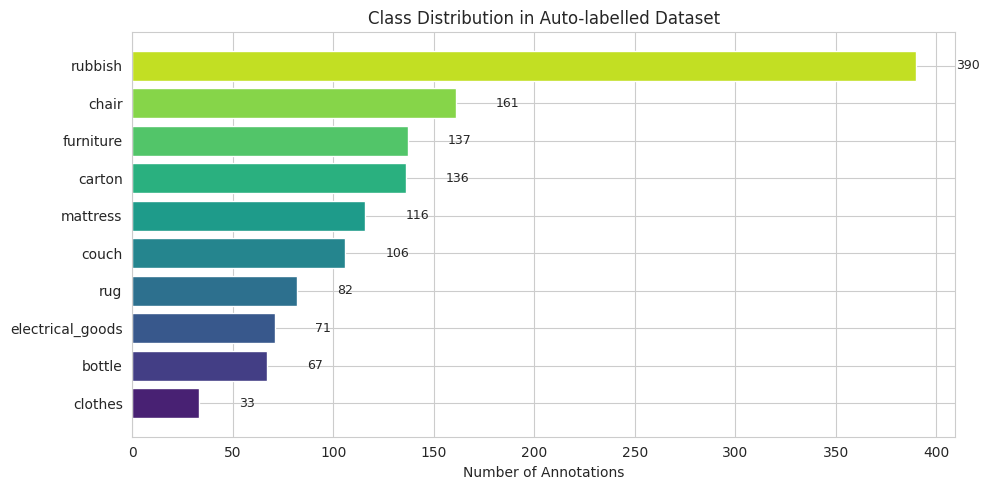

In [5]:
sorted_classes = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)
cls_ids_sorted = [c[0] for c in sorted_classes]
cls_counts_sorted = [c[1] for c in sorted_classes]
cls_names_sorted = [CLASS_NAMES[c] for c in cls_ids_sorted]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(cls_names_sorted[::-1], cls_counts_sorted[::-1], color=sns.color_palette("viridis", NUM_CLASSES))
ax.set_xlabel("Number of Annotations")
ax.set_title("Class Distribution in Auto-labelled Dataset")
for bar, count in zip(bars, cls_counts_sorted[::-1]):
    ax.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2, str(count),
            va="center", fontsize=9)
plt.tight_layout()
plt.show()

### Sample images with bounding boxes

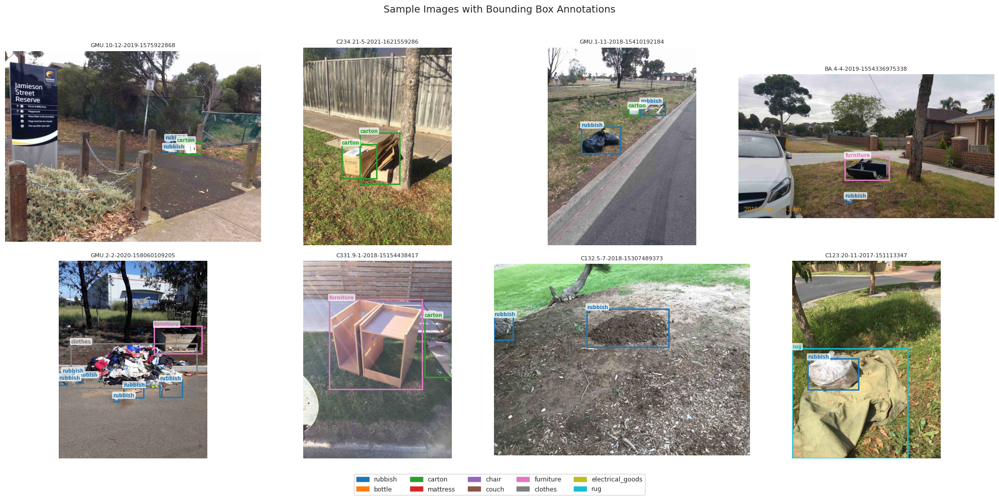

In [6]:
# Build a color map for classes
CMAP = plt.cm.get_cmap("tab10", NUM_CLASSES)
CLASS_COLORS = {i: CMAP(i) for i in range(NUM_CLASSES)}


def find_image_for_stem(stem):
    """Find the image file matching a label stem."""
    for ext in (".jpg", ".jpeg", ".png"):
        p = RUBBISH_DIR / (stem + ext)
        if p.exists():
            return p
    return None


def draw_boxes_on_ax(ax, img, boxes, class_names, class_colors):
    """Draw bounding boxes on a matplotlib axis."""
    ax.imshow(img)
    h, w = img.shape[:2] if isinstance(img, np.ndarray) else (img.height, img.width)
    if isinstance(img, Image.Image):
        w, h = img.size
        img_arr = np.array(img)
        ax.imshow(img_arr)

    for cls_id, cx, cy, bw, bh in boxes:
        x1 = (cx - bw / 2) * w
        y1 = (cy - bh / 2) * h
        rect_w = bw * w
        rect_h = bh * h
        color = class_colors.get(cls_id, (1, 0, 0, 1))
        rect = patches.Rectangle((x1, y1), rect_w, rect_h,
                                 linewidth=2, edgecolor=color, facecolor="none")
        ax.add_patch(rect)
        ax.text(x1, y1 - 3, class_names[cls_id], color=color,
                fontsize=7, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", alpha=0.7))
    ax.axis("off")


# Pick 8 samples that have bounding boxes
samples_with_boxes = [stem for stem, boxes in all_labels.items() if len(boxes) >= 2]
random.shuffle(samples_with_boxes)
samples_to_show = samples_with_boxes[:8]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, stem in zip(axes.flat, samples_to_show):
    img_path = find_image_for_stem(stem)
    if img_path is None:
        ax.axis("off")
        continue
    img = Image.open(img_path).convert("RGB")
    draw_boxes_on_ax(ax, img, all_labels[stem], CLASS_NAMES, CLASS_COLORS)
    ax.set_title(stem[:25], fontsize=8)

# Add legend
legend_patches = [patches.Patch(color=CLASS_COLORS[i], label=CLASS_NAMES[i]) for i in range(NUM_CLASSES)]
fig.legend(handles=legend_patches, loc="lower center", ncol=5, fontsize=9)
fig.suptitle("Sample Images with Bounding Box Annotations", fontsize=14)
plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

### Summary statistics

In [7]:
# Annotations per image distribution
annots_per_image = [len(b) for b in all_labels.values() if len(b) > 0]

summary = pd.DataFrame({
    "Metric": [
        "Total rubbish images", "Total not-rubbish images",
        "Total label files", "Empty label files", "Total annotations",
        "Mean annotations/image (non-empty)", "Max annotations/image"
    ],
    "Value": [
        len(rubbish_images), len(not_rubbish_images),
        len(label_files), empty_labels, total_annotations,
        f"{np.mean(annots_per_image):.1f}", max(annots_per_image)
    ]
})
summary.style.hide(axis="index")

Metric,Value
Total rubbish images,666
Total not-rubbish images,6554
Total label files,667
Empty label files,1
Total annotations,1299
Mean annotations/image (non-empty),2.0
Max annotations/image,11


## 4. Prepare Base Dataset Split

- Match images to labels (skip labels with no image)
- Use all rubbish images with labels
- Sample from not_rubbish/ to reach 1,100 total
- Stratified train/val/test split (20% test, 10% val, 70% train)

In [8]:
# Build mapping: stem -> image_path for rubbish images
rubbish_stem_map = {}
for p in rubbish_images:
    rubbish_stem_map[p.stem] = p

# Matched rubbish images (have a label file AND an image)
matched_rubbish = []
skipped_no_image = 0

for stem, boxes in all_labels.items():
    img_path = rubbish_stem_map.get(stem)
    if img_path is None:
        # Try to find image in rubbish dir
        img_path = find_image_for_stem(stem)
    if img_path is not None and img_path.exists():
        matched_rubbish.append((img_path, boxes, stem))
    else:
        skipped_no_image += 1

# Filter to only non-empty label images for rubbish
rubbish_with_objects = [(p, b, s) for p, b, s in matched_rubbish if len(b) > 0]
rubbish_empty = [(p, b, s) for p, b, s in matched_rubbish if len(b) == 0]

n_rubbish = len(rubbish_with_objects)
n_needed = 1200 - n_rubbish

f"Rubbish with objects: {n_rubbish}, Skipped (no image): {skipped_no_image}, Not-rubbish to sample: {n_needed}"

'Rubbish with objects: 666, Skipped (no image): 1, Not-rubbish to sample: 534'

In [9]:
# Sample not_rubbish images
random.seed(SEED)
not_rubbish_sampled = random.sample(not_rubbish_images, min(n_needed, len(not_rubbish_images)))

# Build the full dataset list: (image_path, boxes, stem, is_rubbish)
dataset_entries = []
for img_path, boxes, stem in rubbish_with_objects:
    dataset_entries.append({"image": img_path, "boxes": boxes, "stem": stem, "is_rubbish": True})
for img_path in not_rubbish_sampled:
    dataset_entries.append({"image": img_path, "boxes": [], "stem": img_path.stem, "is_rubbish": False})

f"Total dataset size: {len(dataset_entries)} (rubbish: {n_rubbish}, not-rubbish: {len(not_rubbish_sampled)})"

'Total dataset size: 1200 (rubbish: 666, not-rubbish: 534)'

In [10]:
# Stratified splitting using multi-label representation
# Each image gets a binary vector of length NUM_CLASSES + 1 (last = negative/no rubbish)
multilabel_matrix = np.zeros((len(dataset_entries), NUM_CLASSES + 1), dtype=int)

for i, entry in enumerate(dataset_entries):
    if not entry["boxes"]:
        multilabel_matrix[i, NUM_CLASSES] = 1  # negative class
    else:
        for cls_id, *_ in entry["boxes"]:
            multilabel_matrix[i, cls_id] = 1

indices = np.arange(len(dataset_entries))

# First split: separate test set (20%)
splitter1 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_val_idx, test_idx = next(splitter1.split(indices, multilabel_matrix))

# Second split: separate val set (10% of total ≈ 12.5% of remaining 80%)
val_frac = 0.1 / 0.8  # 10% of total from the remaining 80%
splitter2 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=val_frac, random_state=SEED)
train_idx, val_idx = next(splitter2.split(train_val_idx, multilabel_matrix[train_val_idx]))
train_idx = train_val_idx[train_idx]
val_idx = train_val_idx[val_idx]

split_map = {}
for i in train_idx:
    split_map[i] = "train"
for i in val_idx:
    split_map[i] = "val"
for i in test_idx:
    split_map[i] = "test"

for entry_idx, entry in enumerate(dataset_entries):
    entry["split"] = split_map[entry_idx]

n = len(dataset_entries)
split_counts = Counter(e["split"] for e in dataset_entries)
f"Train: {split_counts['train']} ({split_counts['train']/n:.0%}), Val: {split_counts['val']} ({split_counts['val']/n:.0%}), Test: {split_counts['test']} ({split_counts['test']/n:.0%})"


'Train: 843 (70%), Val: 117 (10%), Test: 240 (20%)'

### Split distribution visualization

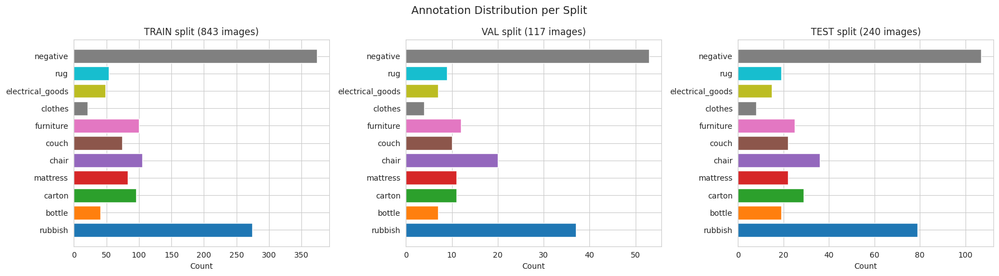

In [11]:
# Class distribution per split
split_class_counts = {s: Counter() for s in ["train", "val", "test"]}
split_neg_counts = Counter()

for entry in dataset_entries:
    s = entry["split"]
    if not entry["boxes"]:
        split_neg_counts[s] += 1
    for cls_id, *_ in entry["boxes"]:
        split_class_counts[s][cls_id] += 1

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, split_name in zip(axes, ["train", "val", "test"]):
    counts = split_class_counts[split_name]
    names = [CLASS_NAMES[i] for i in range(NUM_CLASSES)] + ["negative"]
    vals = [counts.get(i, 0) for i in range(NUM_CLASSES)] + [split_neg_counts[split_name]]
    colors = [CLASS_COLORS[i] for i in range(NUM_CLASSES)] + [(0.5, 0.5, 0.5, 1.0)]
    ax.barh(names, vals, color=colors)
    ax.set_title(f"{split_name.upper()} split ({split_counts[split_name]} images)")
    ax.set_xlabel("Count")

plt.suptitle("Annotation Distribution per Split", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Stage 1 — Binary Rubbish Detector

### 5a. Prepare Binary YOLO Dataset

Convert all multi-class labels to class 0 ("rubbish"). Not-rubbish images keep empty labels.

In [12]:
BINARY_DS = ROOT / "dataset_binary"

for split_name in ["train", "val", "test"]:
    (BINARY_DS / split_name / "images").mkdir(parents=True, exist_ok=True)
    (BINARY_DS / split_name / "labels").mkdir(parents=True, exist_ok=True)

for entry in tqdm(dataset_entries, desc="Creating binary dataset"):
    split_name = entry["split"]
    img_src = entry["image"]
    stem = entry["stem"]
    dst_img = BINARY_DS / split_name / "images" / img_src.name
    dst_lbl = BINARY_DS / split_name / "labels" / (stem + ".txt")

    # Copy image (use symlink for speed, fallback to copy)
    if not dst_img.exists():
        shutil.copy2(img_src, dst_img)

    # Write binary label: all boxes become class 0
    lines = []
    for cls_id, cx, cy, w, h in entry["boxes"]:
        lines.append(f"0 {cx} {cy} {w} {h}")
    dst_lbl.write_text("\n".join(lines))

# Write data.yaml
data_yaml = BINARY_DS / "data.yaml"
data_yaml.write_text(
    f"path: {BINARY_DS.resolve()}\n"
    f"train: train/images\n"
    f"val: val/images\n"
    f"test: test/images\n"
    f"names:\n  0: rubbish\n"
)

"Binary YOLO dataset created."

Creating binary dataset:   0%|          | 0/1200 [00:00<?, ?it/s]

'Binary YOLO dataset created.'

### Binary dataset distribution

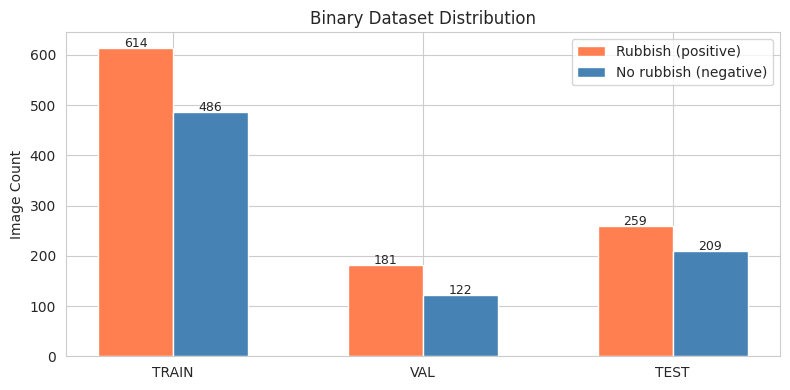

In [13]:
binary_stats = {}
for split_name in ["train", "val", "test"]:
    lbl_dir = BINARY_DS / split_name / "labels"
    n_pos = sum(1 for f in lbl_dir.glob("*.txt") if f.read_text().strip())
    n_neg = sum(1 for f in lbl_dir.glob("*.txt") if not f.read_text().strip())
    binary_stats[split_name] = {"positive": n_pos, "negative": n_neg}

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(3)
splits = ["train", "val", "test"]
pos = [binary_stats[s]["positive"] for s in splits]
neg = [binary_stats[s]["negative"] for s in splits]
ax.bar(x - 0.15, pos, 0.3, label="Rubbish (positive)", color="coral")
ax.bar(x + 0.15, neg, 0.3, label="No rubbish (negative)", color="steelblue")
ax.set_xticks(x)
ax.set_xticklabels([s.upper() for s in splits])
ax.set_ylabel("Image Count")
ax.set_title("Binary Dataset Distribution")
ax.legend()
for i, (p, n) in enumerate(zip(pos, neg)):
    ax.text(i - 0.15, p + 2, str(p), ha="center", fontsize=9)
    ax.text(i + 0.15, n + 2, str(n), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

### 5b. Train Binary YOLO11 Models (3 sizes)

In [14]:
from ultralytics import YOLO

COMMON_TRAIN_ARGS = dict(
    data=str(data_yaml.resolve()),
    imgsz=960,
    epochs=200,
    patience=25,
    cos_lr=True,
    lr0=0.01,
    lrf=0.01,
    warmup_epochs=3,
    mosaic=1.0,
    mixup=0.15,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=10,
    translate=0.1,
    scale=0.5,
    perspective=0.001,
    close_mosaic=10,
    freeze=10,
    seed=SEED,
    verbose=True,
)

BINARY_MODELS_CFG = [
    {"name": "yolo11s_binary", "model": "yolo11s.pt", "batch": 32},
    {"name": "yolo11m_binary", "model": "yolo11m.pt", "batch": 24},
    {"name": "yolo11l_binary", "model": "yolo11l.pt", "batch": 16},
    {"name": "yolo26s_binary", "model": "yolo26s.pt", "batch": 32},
    {"name": "yolo26m_binary", "model": "yolo26m.pt", "batch": 24},
    {"name": "yolo26l_binary", "model": "yolo26l.pt", "batch": 16},
]

In [15]:
import gc, torch

binary_save_dirs = {}
binary_model_paths = {}
binary_val_results = {}

# Train YOLO11s binary
cfg = BINARY_MODELS_CFG[0]
model_s = YOLO(cfg["model"])
results_s = model_s.train(
    **COMMON_TRAIN_ARGS,
    batch=cfg["batch"],
    name=cfg["name"],
)
binary_save_dirs["YOLO11s"] = str(results_s.save_dir)

# Evaluate on test set
best_pt = Path(results_s.save_dir) / "weights" / "best.pt"
binary_model_paths["YOLO11s"] = best_pt
test_model = YOLO(str(best_pt))
binary_val_results["YOLO11s"] = test_model.val(
    data=str(data_yaml.resolve()), split="test", imgsz=960, batch=16, verbose=False,
)
del model_s, results_s, test_model
gc.collect()
torch.cuda.empty_cache()

Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset_binary/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_binary5, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patien

#### YOLO11s training curves

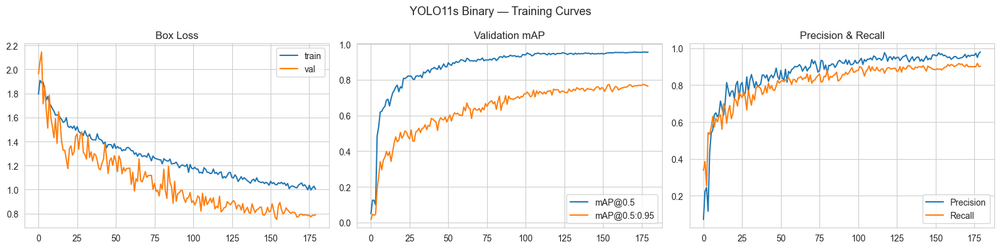

In [16]:
def plot_yolo_training_curves(run_dir, title=""):
    """Plot training curves from YOLO results CSV."""
    csv_path = Path(run_dir) / "results.csv"
    if not csv_path.exists():
        # Try to find it in runs/detect/
        possible = list(Path("runs/detect").glob(f"**/results.csv"))
        if possible:
            csv_path = possible[-1]
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # Box loss
    axes[0].plot(df["train/box_loss"], label="train")
    axes[0].plot(df["val/box_loss"], label="val")
    axes[0].set_title("Box Loss")
    axes[0].legend()

    # mAP
    axes[1].plot(df["metrics/mAP50(B)"], label="mAP@0.5")
    axes[1].plot(df["metrics/mAP50-95(B)"], label="mAP@0.5:0.95")
    axes[1].set_title("Validation mAP")
    axes[1].legend()

    # Precision & Recall
    axes[2].plot(df["metrics/precision(B)"], label="Precision")
    axes[2].plot(df["metrics/recall(B)"], label="Recall")
    axes[2].set_title("Precision & Recall")
    axes[2].legend()

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


plot_yolo_training_curves(binary_save_dirs["YOLO11s"], "YOLO11s Binary — Training Curves")

In [17]:
# Train YOLO11m binary
cfg = BINARY_MODELS_CFG[1]
model_m = YOLO(cfg["model"])
results_m = model_m.train(
    **COMMON_TRAIN_ARGS,
    batch=cfg["batch"],
    name=cfg["name"],
)
binary_save_dirs["YOLO11m"] = str(results_m.save_dir)

# Evaluate on test set
best_pt = Path(results_m.save_dir) / "weights" / "best.pt"
binary_model_paths["YOLO11m"] = best_pt
test_model = YOLO(str(best_pt))
binary_val_results["YOLO11m"] = test_model.val(
    data=str(data_yaml.resolve()), split="test", imgsz=960, batch=16, verbose=False,
)
del model_m, results_m, test_model
gc.collect()
torch.cuda.empty_cache()


Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=24, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset_binary/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11m_binary3, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patien

#### YOLO11m training curves

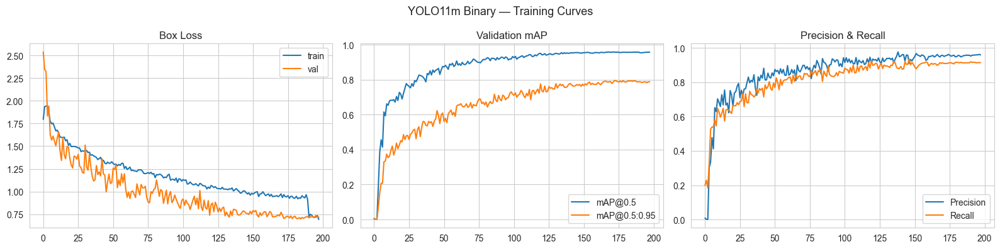

In [18]:
plot_yolo_training_curves(binary_save_dirs["YOLO11m"], "YOLO11m Binary — Training Curves")

In [19]:
# Train YOLO11l binary
cfg = BINARY_MODELS_CFG[2]
model_l = YOLO(cfg["model"])
results_l = model_l.train(
    **COMMON_TRAIN_ARGS,
    batch=cfg["batch"],
    name=cfg["name"],
)
binary_save_dirs["YOLO11l"] = str(results_l.save_dir)

# Evaluate on test set
best_pt = Path(results_l.save_dir) / "weights" / "best.pt"
binary_model_paths["YOLO11l"] = best_pt
test_model = YOLO(str(best_pt))
binary_val_results["YOLO11l"] = test_model.val(
    data=str(data_yaml.resolve()), split="test", imgsz=960, batch=16, verbose=False,
)
del model_l, results_l, test_model
gc.collect()
torch.cuda.empty_cache()

Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset_binary/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo11l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11l_binary2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patien

#### YOLO11l training curves

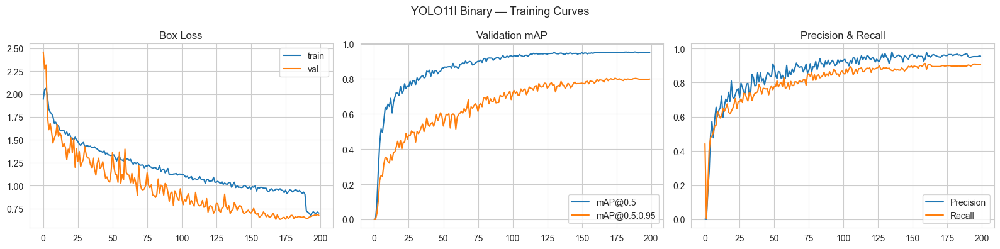

In [20]:
plot_yolo_training_curves(binary_save_dirs["YOLO11l"], "YOLO11l Binary — Training Curves")

#### Train YOLO26s binary

In [21]:
# Train YOLO26s binary
cfg = BINARY_MODELS_CFG[3]
model_s26 = YOLO(cfg["model"])
results_s26 = model_s26.train(
    **COMMON_TRAIN_ARGS,
    batch=cfg["batch"],
    name=cfg["name"],
)
binary_save_dirs["YOLO26s"] = str(results_s26.save_dir)

# Evaluate on test set
best_pt = Path(results_s26.save_dir) / "weights" / "best.pt"
binary_model_paths["YOLO26s"] = best_pt
test_model = YOLO(str(best_pt))
binary_val_results["YOLO26s"] = test_model.val(
    data=str(data_yaml.resolve()), split="test", imgsz=960, batch=16, verbose=False,
)
del model_s26, results_s26, test_model
gc.collect()
torch.cuda.empty_cache()


Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset_binary/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s_binary2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patien

#### YOLO26s training curves

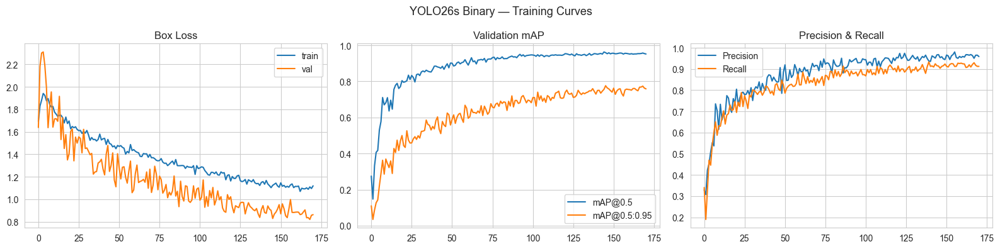

In [22]:
plot_yolo_training_curves(binary_save_dirs["YOLO26s"], "YOLO26s Binary — Training Curves")

#### Train YOLO26m binary

In [23]:
# Train YOLO26m binary
cfg = BINARY_MODELS_CFG[4]
model_m26 = YOLO(cfg["model"])
results_m26 = model_m26.train(
    **COMMON_TRAIN_ARGS,
    batch=cfg["batch"],
    name=cfg["name"],
)
binary_save_dirs["YOLO26m"] = str(results_m26.save_dir)

# Evaluate on test set
best_pt = Path(results_m26.save_dir) / "weights" / "best.pt"
binary_model_paths["YOLO26m"] = best_pt
test_model = YOLO(str(best_pt))
binary_val_results["YOLO26m"] = test_model.val(
    data=str(data_yaml.resolve()), split="test", imgsz=960, batch=16, verbose=False,
)
del model_m26, results_m26, test_model
gc.collect()
torch.cuda.empty_cache()


Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=24, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset_binary/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26m_binary2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patien

#### YOLO26m training curves

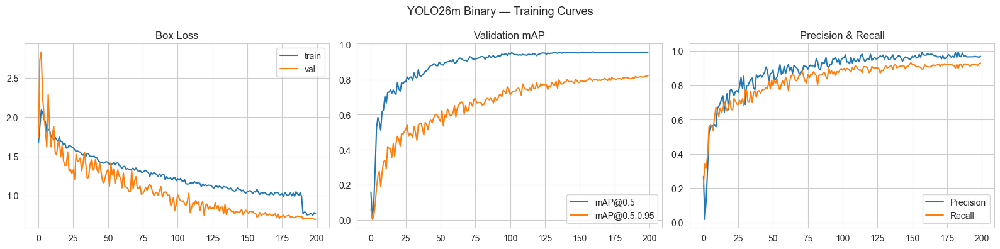

In [24]:
plot_yolo_training_curves(binary_save_dirs["YOLO26m"], "YOLO26m Binary — Training Curves")

#### Train YOLO26l binary

In [25]:
# Train YOLO26l binary
cfg = BINARY_MODELS_CFG[5]
model_l26 = YOLO(cfg["model"])
results_l26 = model_l26.train(
    **COMMON_TRAIN_ARGS,
    batch=cfg["batch"],
    name=cfg["name"],
)
binary_save_dirs["YOLO26l"] = str(results_l26.save_dir)

# Evaluate on test set
best_pt = Path(results_l26.save_dir) / "weights" / "best.pt"
binary_model_paths["YOLO26l"] = best_pt
test_model = YOLO(str(best_pt))
binary_val_results["YOLO26l"] = test_model.val(
    data=str(data_yaml.resolve()), split="test", imgsz=960, batch=16, verbose=False,
)
del model_l26, results_l26, test_model
gc.collect()
torch.cuda.empty_cache()


Ultralytics 8.4.34 🚀 Python-3.12.13 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/dataset_binary/data.yaml, degrees=10, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo26l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26l_binary, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patienc

#### YOLO26l training curves

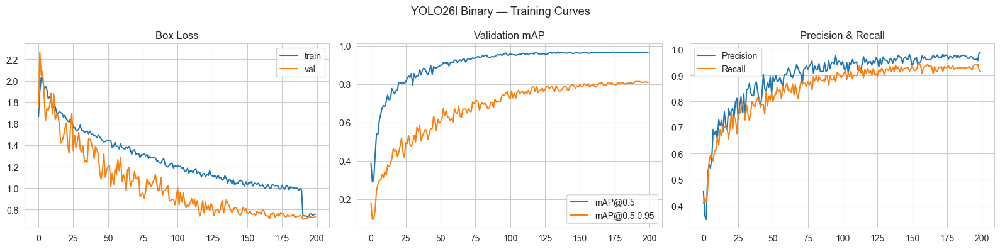

In [26]:
plot_yolo_training_curves(binary_save_dirs["YOLO26l"], "YOLO26l Binary — Training Curves")

### 5c. Evaluate Binary Detectors on Test Set

In [27]:
# Binary test evaluation already done after each training run
for name, val_res in binary_val_results.items():
    mp = val_res.results_dict
    display(f"{name}: mAP@0.5={mp['metrics/mAP50(B)']:.4f}, mAP@0.5:0.95={mp['metrics/mAP50-95(B)']:.4f}")

'YOLO11s: mAP@0.5=0.9142, mAP@0.5:0.95=0.7290'

'YOLO11m: mAP@0.5=0.9225, mAP@0.5:0.95=0.7547'

'YOLO11l: mAP@0.5=0.9139, mAP@0.5:0.95=0.7594'

'YOLO26s: mAP@0.5=0.9118, mAP@0.5:0.95=0.7263'

'YOLO26m: mAP@0.5=0.9325, mAP@0.5:0.95=0.7870'

'YOLO26l: mAP@0.5=0.9258, mAP@0.5:0.95=0.7605'

#### Binary detector comparison table

In [28]:
rows = []
for name, val_res in binary_val_results.items():
    mp = val_res.results_dict
    rows.append({
        "Model": name,
        "Precision": f"{mp['metrics/precision(B)']:.4f}",
        "Recall": f"{mp['metrics/recall(B)']:.4f}",
        "mAP@0.5": f"{mp['metrics/mAP50(B)']:.4f}",
        "mAP@0.5:0.95": f"{mp['metrics/mAP50-95(B)']:.4f}",
    })

binary_comparison_df = pd.DataFrame(rows)
binary_comparison_df.style.hide(axis="index")

Model,Precision,Recall,mAP@0.5,mAP@0.5:0.95
YOLO11s,0.9345,0.8672,0.9142,0.7290
YOLO11m,0.9589,0.8455,0.9225,0.7547
YOLO11l,0.9462,0.8592,0.9139,0.7594
YOLO26s,0.9562,0.8511,0.9118,0.7263
YOLO26m,0.9420,0.8817,0.9325,0.7870
YOLO26l,0.9421,0.8732,0.9258,0.7605


#### Sample binary predictions on test images

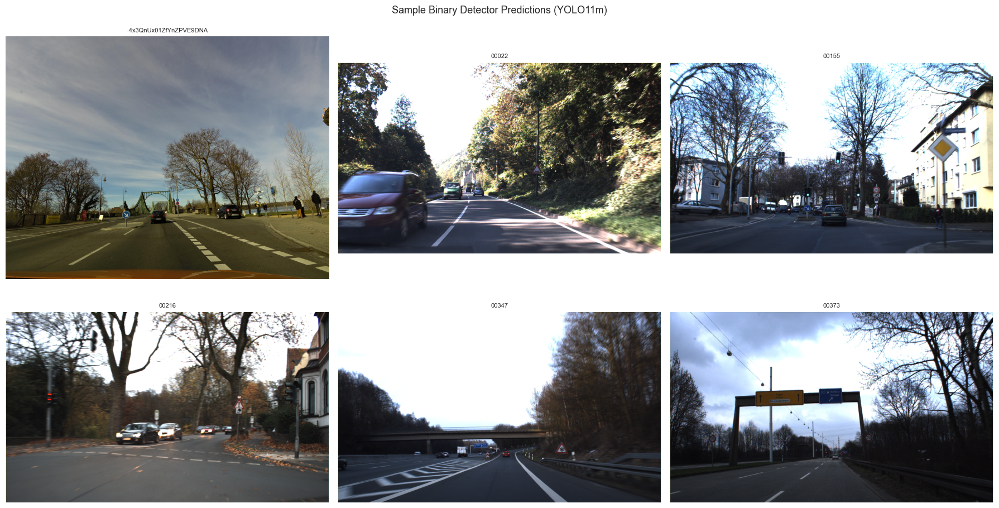

In [29]:
# Use the best medium model for sample visualization
sample_test_imgs = sorted((BINARY_DS / "test" / "images").glob("*"))[:6]
best_binary = YOLO(str(binary_model_paths["YOLO11m"]))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, img_path in zip(axes.flat, sample_test_imgs):
    results = best_binary.predict(str(img_path), imgsz=960, conf=0.25, verbose=False)
    img = Image.open(img_path).convert("RGB")
    ax.imshow(np.array(img))
    if len(results[0].boxes) > 0:
        for box in results[0].boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            conf = box.conf[0].cpu().item()
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                     linewidth=2, edgecolor="lime", facecolor="none")
            ax.add_patch(rect)
            ax.text(x1, y1 - 5, f"rubbish {conf:.2f}", color="lime",
                    fontsize=8, fontweight="bold",
                    bbox=dict(facecolor="black", alpha=0.6, pad=1))
    ax.axis("off")
    ax.set_title(img_path.stem[:30], fontsize=8)

fig.suptitle("Sample Binary Detector Predictions (YOLO11m)", fontsize=13)
plt.tight_layout()
plt.show()

## 6. Stage 2 — Rubbish Type Classifier

### 6a. Prepare Crop Dataset

Crop every annotated bounding box from train/val/test images, expand by 15%, resize to 256x256.

In [30]:
CROPS_DIR = ROOT / "crops"

def crop_bbox(img, cx, cy, bw, bh, expand=0.15):
    """Crop a bounding box from an image with expansion. Returns PIL Image."""
    W, H = img.size
    # Convert normalized coords to pixel
    x_center = cx * W
    y_center = cy * H
    box_w = bw * W
    box_h = bh * H

    # Expand by 15%
    box_w *= (1 + expand)
    box_h *= (1 + expand)

    x1 = max(0, int(x_center - box_w / 2))
    y1 = max(0, int(y_center - box_h / 2))
    x2 = min(W, int(x_center + box_w / 2))
    y2 = min(H, int(y_center + box_h / 2))

    crop = img.crop((x1, y1, x2, y2))
    return crop.resize((256, 256), Image.BILINEAR)


# Create crops for each split
crop_records = {"train": [], "val": [], "test": []}

for split_name in ["train", "val", "test"]:
    split_dir = CROPS_DIR / split_name
    for cls_id in range(NUM_CLASSES):
        (split_dir / str(cls_id)).mkdir(parents=True, exist_ok=True)

entries_by_split = defaultdict(list)
for entry in dataset_entries:
    if entry["boxes"]:  # only images with annotations
        entries_by_split[entry["split"]].append(entry)

crop_idx = 0
for split_name in ["train", "val", "test"]:
    for entry in tqdm(entries_by_split[split_name], desc=f"Cropping {split_name}"):
        img = Image.open(entry["image"]).convert("RGB")
        for cls_id, cx, cy, bw, bh in entry["boxes"]:
            crop = crop_bbox(img, cx, cy, bw, bh)
            fname = f"crop_{crop_idx:06d}.jpg"
            crop_path = CROPS_DIR / split_name / str(cls_id) / fname
            crop.save(crop_path, quality=95)
            crop_records[split_name].append({"path": crop_path, "class": cls_id})
            crop_idx += 1

for s in ["train", "val", "test"]:
    c = Counter(r["class"] for r in crop_records[s])
    total = sum(c.values())

Cropping train:   0%|          | 0/469 [00:00<?, ?it/s]

Cropping val:   0%|          | 0/64 [00:00<?, ?it/s]

Cropping test:   0%|          | 0/133 [00:00<?, ?it/s]

### Crop count per class (bar chart)

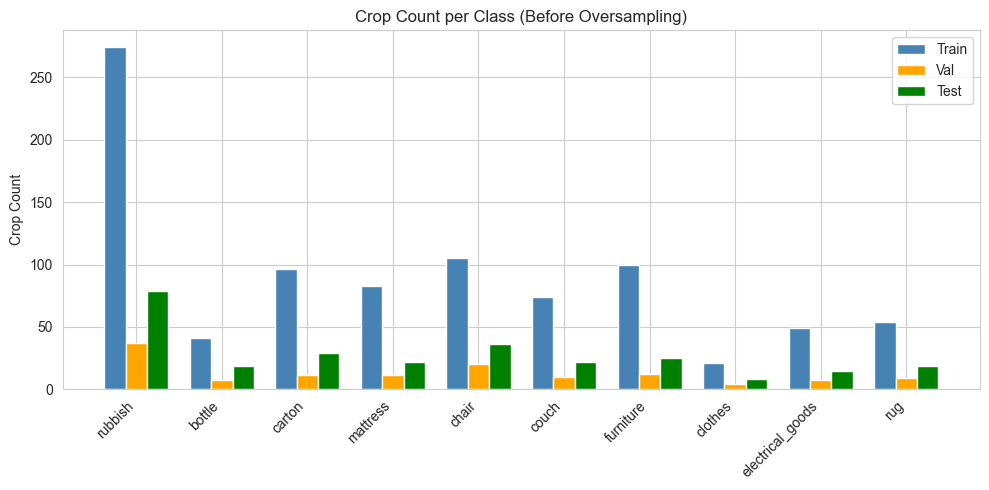

In [31]:
train_crop_counts = Counter(r["class"] for r in crop_records["train"])
val_crop_counts = Counter(r["class"] for r in crop_records["val"])
test_crop_counts = Counter(r["class"] for r in crop_records["test"])

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(NUM_CLASSES)
w = 0.25
train_vals = [train_crop_counts.get(i, 0) for i in range(NUM_CLASSES)]
val_vals = [val_crop_counts.get(i, 0) for i in range(NUM_CLASSES)]
test_vals = [test_crop_counts.get(i, 0) for i in range(NUM_CLASSES)]

ax.bar(x - w, train_vals, w, label="Train", color="steelblue")
ax.bar(x, val_vals, w, label="Val", color="orange")
ax.bar(x + w, test_vals, w, label="Test", color="green")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("Crop Count")
ax.set_title("Crop Count per Class (Before Oversampling)")
ax.legend()
plt.tight_layout()
plt.show()

### Handle class imbalance: oversample minority classes in training set

In [32]:
from PIL import ImageEnhance, ImageFilter

def augment_crop(img):
    """Apply random augmentations to a crop for oversampling."""
    # Random horizontal flip
    if random.random() > 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
    # Random rotation
    angle = random.uniform(-15, 15)
    img = img.rotate(angle, fillcolor=(128, 128, 128))
    # Color jitter
    if random.random() > 0.3:
        enhancer = ImageEnhance.Brightness(img)
        img = enhancer.enhance(random.uniform(0.8, 1.2))
    if random.random() > 0.3:
        enhancer = ImageEnhance.Contrast(img)
        img = enhancer.enhance(random.uniform(0.8, 1.2))
    if random.random() > 0.3:
        enhancer = ImageEnhance.Color(img)
        img = enhancer.enhance(random.uniform(0.8, 1.3))
    return img


# Compute target count: median of class counts
median_count = int(np.median(list(train_crop_counts.values())))
minority_classes = [i for i in range(NUM_CLASSES) if train_crop_counts.get(i, 0) < median_count]

aug_idx = 0
for cls_id in tqdm(minority_classes, desc="Oversampling minority classes"):
    current_count = train_crop_counts.get(cls_id, 0)
    needed = median_count - current_count
    if needed <= 0:
        continue

    # Get existing crops of this class
    existing = [r for r in crop_records["train"] if r["class"] == cls_id]
    if not existing:
        continue

    for i in range(needed):
        src = random.choice(existing)
        img = Image.open(src["path"]).convert("RGB")
        aug_img = augment_crop(img)
        fname = f"aug_{aug_idx:06d}.jpg"
        aug_path = CROPS_DIR / "train" / str(cls_id) / fname
        aug_img.save(aug_path, quality=95)
        crop_records["train"].append({"path": aug_path, "class": cls_id})
        aug_idx += 1

f"Created {aug_idx} augmented crops for minority classes"

Oversampling minority classes:   0%|          | 0/5 [00:00<?, ?it/s]

'Created 151 augmented crops for minority classes'

### Updated distribution after oversampling

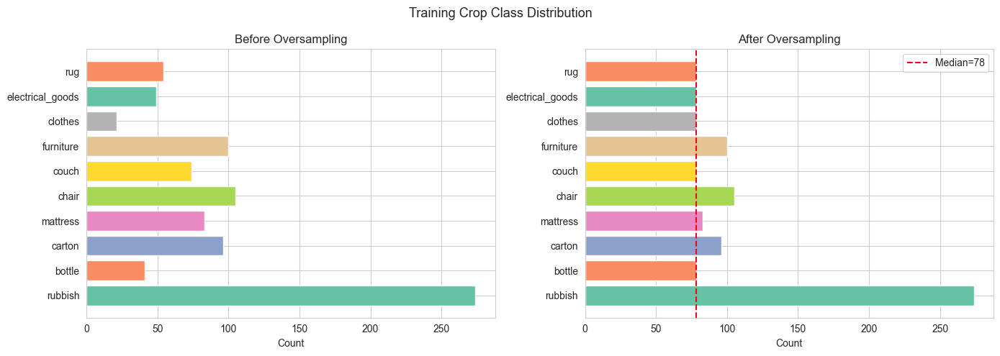

In [33]:
updated_train_counts = Counter(r["class"] for r in crop_records["train"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before
axes[0].barh([CLASS_NAMES[i] for i in range(NUM_CLASSES)],
             [train_crop_counts.get(i, 0) for i in range(NUM_CLASSES)],
             color=sns.color_palette("Set2", NUM_CLASSES))
axes[0].set_title("Before Oversampling")
axes[0].set_xlabel("Count")

# After
axes[1].barh([CLASS_NAMES[i] for i in range(NUM_CLASSES)],
             [updated_train_counts.get(i, 0) for i in range(NUM_CLASSES)],
             color=sns.color_palette("Set2", NUM_CLASSES))
axes[1].set_title("After Oversampling")
axes[1].set_xlabel("Count")
axes[1].axvline(median_count, color="red", linestyle="--", label=f"Median={median_count}")
axes[1].legend()

plt.suptitle("Training Crop Class Distribution", fontsize=13)
plt.tight_layout()
plt.show()

### Sample crops per class

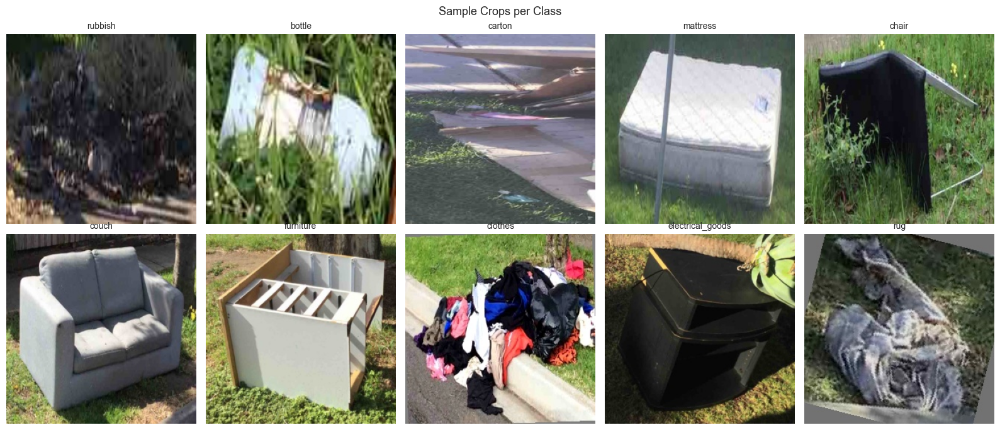

In [34]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for cls_id, ax in enumerate(axes.flat):
    class_crops = [r for r in crop_records["train"] if r["class"] == cls_id]
    if class_crops:
        sample = random.choice(class_crops)
        img = Image.open(sample["path"])
        ax.imshow(img)
    ax.set_title(CLASS_NAMES[cls_id], fontsize=10)
    ax.axis("off")

fig.suptitle("Sample Crops per Class", fontsize=13)
plt.tight_layout()
plt.show()

### 6b. Build PyTorch Dataset & DataLoaders

In [35]:
# ImageNet stats
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def get_train_transform(img_size=256):
    return A.Compose([
        A.RandomResizedCrop(size=(img_size, img_size), scale=(0.8, 1.0)),
        A.HorizontalFlip(p=0.5),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.5),
        A.Rotate(limit=10, p=0.5),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])


def get_val_transform(img_size=256):
    return A.Compose([
        A.Resize(height=img_size, width=img_size),
        A.CenterCrop(height=img_size, width=img_size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])


class CropDataset(Dataset):
    """PyTorch Dataset for cropped rubbish regions."""

    def __init__(self, records, transform=None):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = Image.open(rec["path"]).convert("RGB")
        img = np.array(img)
        label = rec["class"]

        if self.transform:
            transformed = self.transform(image=img)
            img = transformed["image"]
        else:
            img = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0

        return img, label


def build_weighted_sampler(records, num_classes=NUM_CLASSES):
    """Build a WeightedRandomSampler using inverse sqrt class frequency."""
    class_counts = Counter(r["class"] for r in records)
    total = sum(class_counts.values())
    # Inverse sqrt frequency weights
    class_weights = {c: 1.0 / np.sqrt(count) for c, count in class_counts.items()}
    sample_weights = [class_weights[r["class"]] for r in records]
    return WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

In [36]:
def create_dataloaders(train_records, val_records, test_records, img_size=256, batch_size=32):
    """Create train/val/test DataLoaders."""
    train_ds = CropDataset(train_records, get_train_transform(img_size))
    val_ds = CropDataset(val_records, get_val_transform(img_size))
    test_ds = CropDataset(test_records, get_val_transform(img_size))

    sampler = build_weighted_sampler(train_records)

    train_loader = DataLoader(train_ds, batch_size=batch_size, sampler=sampler,
                              num_workers=0, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                            num_workers=0, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                             num_workers=0, pin_memory=True)

    return train_loader, val_loader, test_loader

### 6c. Train EfficientNetV2 Classifiers (3 sizes)

Training loop with freeze strategy, warmup, early stopping, and label smoothing.

In [37]:
def get_class_weights(records):
    """Compute inverse sqrt frequency class weights for CrossEntropyLoss."""
    counts = Counter(r["class"] for r in records)
    weights = torch.zeros(NUM_CLASSES)
    for c in range(NUM_CLASSES):
        weights[c] = 1.0 / np.sqrt(counts.get(c, 1))
    # Normalize so they sum to NUM_CLASSES
    weights = weights / weights.sum() * NUM_CLASSES
    return weights


def create_model(model_name, num_classes=NUM_CLASSES):
    """Create a timm model with the correct number of output classes."""
    model = timm.create_model(model_name, pretrained=True, num_classes=num_classes)
    return model


def freeze_backbone(model):
    """Freeze all parameters except the classifier head."""
    for name, param in model.named_parameters():
        if "classifier" not in name and "head" not in name and "fc" not in name:
            param.requires_grad = False


def unfreeze_all(model):
    """Unfreeze all parameters."""
    for param in model.parameters():
        param.requires_grad = True


def get_lr_with_warmup(optimizer, epoch, warmup_epochs, base_lr):
    """Linear warmup for the first few epochs."""
    if epoch < warmup_epochs:
        lr = base_lr * (epoch + 1) / warmup_epochs
        for pg in optimizer.param_groups:
            pg["lr"] = lr


def train_one_epoch(model, loader, criterion, optimizer, device):
    """Train for one epoch. Returns average loss and accuracy."""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(loader, desc="  Train", leave=False)
    for images, labels in pbar:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{correct/total:.3f}")

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    """Evaluate model. Returns average loss, accuracy, all predictions and labels."""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    for images, labels in tqdm(loader, desc="  Eval", leave=False):
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    return running_loss / total, correct / total, np.array(all_preds), np.array(all_labels)

In [38]:
def train_classifier(model_name, train_records, val_records, img_size, lr, epochs=60,
                     batch_size=32, warmup_epochs=5, freeze_epochs=5, patience=10,
                     save_name="best_classifier"):
    """Full training pipeline for a classifier."""

    # Create dataloaders
    train_loader, val_loader, _ = create_dataloaders(
        train_records, val_records, val_records, img_size=img_size, batch_size=batch_size
    )

    # Create model
    model = create_model(model_name).to(DEVICE)

    # Class weights for loss
    class_weights = get_class_weights(train_records).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)

    # Optimizer
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    # Scheduler (CosineAnnealing after warmup)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs - warmup_epochs, eta_min=1e-6)

    # Freeze backbone initially
    freeze_backbone(model)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
    best_val_loss = float("inf")
    patience_counter = 0
    best_path = CROPS_DIR / f"{save_name}.pt"

    for epoch in range(epochs):
        # Unfreeze backbone after freeze_epochs
        if epoch == freeze_epochs:
            unfreeze_all(model)
            # Re-create optimizer with all params
            optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
            scheduler = optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=epochs - epoch, eta_min=1e-6
            )

        # Warmup
        if epoch < warmup_epochs:
            get_lr_with_warmup(optimizer, epoch, warmup_epochs, lr)

        current_lr = optimizer.param_groups[0]["lr"]

        # Train
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)

        # Validate
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, DEVICE)

        # Step scheduler (after warmup)
        if epoch >= warmup_epochs:
            scheduler.step()

        # Record history
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["lr"].append(current_lr)

        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save(model.state_dict(), best_path)
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    # Load best weights
    model.load_state_dict(torch.load(best_path, map_location=DEVICE))

    return model, history, best_path

In [39]:
def plot_classifier_curves(history, title=""):
    """Plot training curves for classifier."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Val")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"], label="Val")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    axes[2].plot(history["lr"])
    axes[2].set_title("Learning Rate")
    axes[2].set_xlabel("Epoch")

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


CLASSIFIER_CONFIGS = [
    {
        "name": "EfficientNetV2-S",
        "model_name": "tf_efficientnetv2_s.in21k_ft_in1k",
        "img_size": 256,
        "lr": 2e-4,
        "batch_size": 32,
    },
    {
        "name": "EfficientNetV2-M",
        "model_name": "tf_efficientnetv2_m.in21k_ft_in1k",
        "img_size": 320,
        "lr": 2e-4,
        "batch_size": 24,
    },
    {
        "name": "EfficientNetV2-L",
        "model_name": "tf_efficientnetv2_l.in21k_ft_in1k",
        "img_size": 384,
        "lr": 1e-4,
        "batch_size": 16,
    },
]

def evaluate_classifier_full(model, test_records, img_size, batch_size=32, title=""):
    """Full evaluation: accuracy, macro F1, confusion matrix, per-class accuracy."""
    _, _, test_loader = create_dataloaders(
        test_records, test_records, test_records, img_size=img_size, batch_size=batch_size
    )
    class_weights = get_class_weights(test_records).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)

    _, acc, preds, labels = evaluate(model, test_loader, criterion, DEVICE)
    macro_f1 = f1_score(labels, preds, average="macro")
    per_class_f1 = f1_score(labels, preds, average=None, labels=list(range(NUM_CLASSES)))

    # Confusion matrix
    cm = confusion_matrix(labels, preds, labels=list(range(NUM_CLASSES)))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Confusion matrix heatmap
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    axes[0].set_title(f"{title} — Confusion Matrix")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("True")
    axes[0].tick_params(axis="x", rotation=45)
    axes[0].tick_params(axis="y", rotation=0)

    # Per-class F1
    axes[1].barh(CLASS_NAMES, per_class_f1, color=sns.color_palette("viridis", NUM_CLASSES))
    axes[1].set_xlim(0, 1)
    axes[1].set_title(f"{title} — Per-Class F1 Score")
    axes[1].set_xlabel("F1 Score")

    plt.tight_layout()
    plt.show()

    return {"accuracy": acc, "macro_f1": macro_f1, "per_class_f1": per_class_f1}

model.safetensors:   0%|          | 0.00/86.5M [00:00<?, ?B/s]

  Train:   0%|          | 0/33 [00:00<?, ?it/s]

  Eval:   0%|          | 0/4 [00:00<?, ?it/s]

  Train:   0%|          | 0/33 [00:00<?, ?it/s]

  Eval:   0%|          | 0/4 [00:00<?, ?it/s]

  Train:   0%|          | 0/33 [00:00<?, ?it/s]

... (76 outputs left out)

  Eval:   0%|          | 0/4 [00:00<?, ?it/s]

  Train:   0%|          | 0/33 [00:00<?, ?it/s]

  Eval:   0%|          | 0/4 [00:00<?, ?it/s]

  Eval:   0%|          | 0/9 [00:00<?, ?it/s]

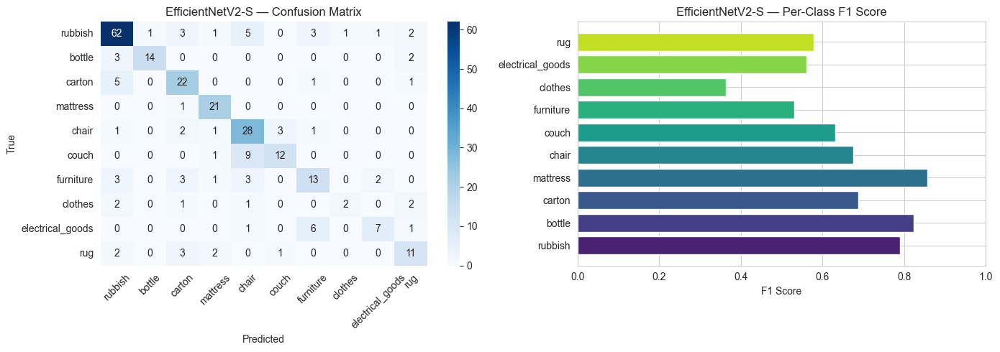

In [40]:
clf_results = {}

# Train EfficientNetV2-S
cfg = CLASSIFIER_CONFIGS[0]
clf_model_s, hist_s, path_s = train_classifier(
    cfg["model_name"], crop_records["train"], crop_records["val"],
    img_size=cfg["img_size"], lr=cfg["lr"], batch_size=cfg["batch_size"],
    save_name="effnetv2_s"
)

# Evaluate on test set
clf_results["EfficientNetV2-S"] = evaluate_classifier_full(
    clf_model_s, crop_records["test"], img_size=256, title="EfficientNetV2-S"
)
del clf_model_s
gc.collect()
torch.cuda.empty_cache()

#### EfficientNetV2-S training curves

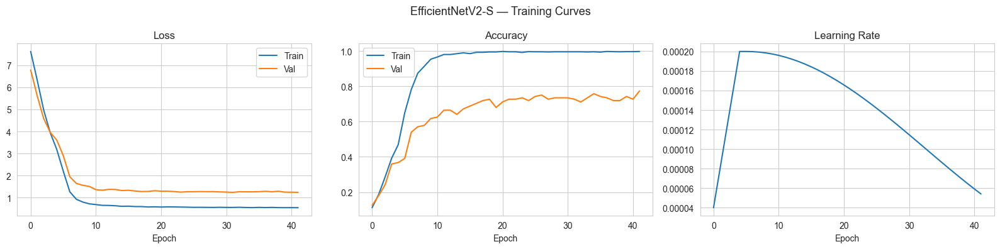

In [41]:
plot_classifier_curves(hist_s, "EfficientNetV2-S — Training Curves")

model.safetensors:   0%|          | 0.00/218M [00:00<?, ?B/s]

  Train:   0%|          | 0/44 [00:00<?, ?it/s]

  Eval:   0%|          | 0/6 [00:00<?, ?it/s]

  Train:   0%|          | 0/44 [00:00<?, ?it/s]

  Eval:   0%|          | 0/6 [00:00<?, ?it/s]

  Train:   0%|          | 0/44 [00:00<?, ?it/s]

... (52 outputs left out)

  Eval:   0%|          | 0/6 [00:00<?, ?it/s]

  Train:   0%|          | 0/44 [00:00<?, ?it/s]

  Eval:   0%|          | 0/6 [00:00<?, ?it/s]

  Eval:   0%|          | 0/9 [00:00<?, ?it/s]

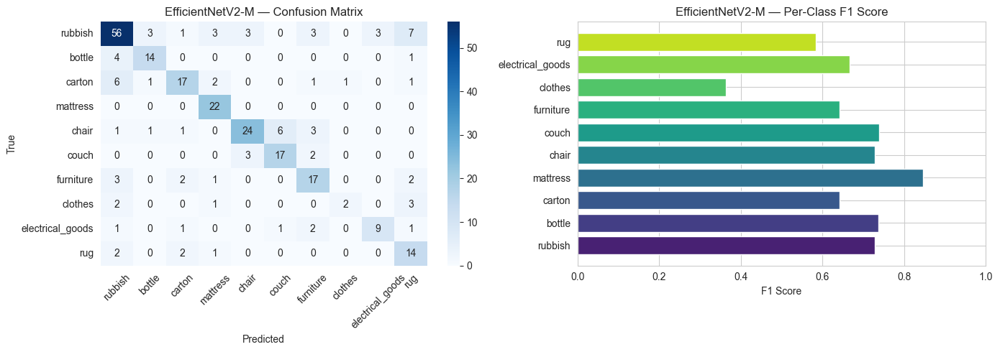

In [42]:
# Train EfficientNetV2-M
cfg = CLASSIFIER_CONFIGS[1]
clf_model_m, hist_m, path_m = train_classifier(
    cfg["model_name"], crop_records["train"], crop_records["val"],
    img_size=cfg["img_size"], lr=cfg["lr"], batch_size=cfg["batch_size"],
    save_name="effnetv2_m"
)

# Evaluate on test set
clf_results["EfficientNetV2-M"] = evaluate_classifier_full(
    clf_model_m, crop_records["test"], img_size=320, title="EfficientNetV2-M"
)
del clf_model_m
gc.collect()
torch.cuda.empty_cache()

#### EfficientNetV2-M training curves

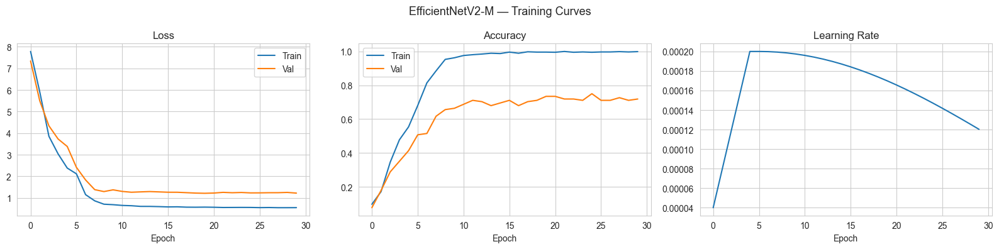

In [43]:
plot_classifier_curves(hist_m, "EfficientNetV2-M — Training Curves")

model.safetensors:   0%|          | 0.00/476M [00:00<?, ?B/s]

  Train:   0%|          | 0/66 [00:00<?, ?it/s]

  Eval:   0%|          | 0/8 [00:00<?, ?it/s]

  Train:   0%|          | 0/66 [00:00<?, ?it/s]

  Eval:   0%|          | 0/8 [00:00<?, ?it/s]

  Train:   0%|          | 0/66 [00:00<?, ?it/s]

... (36 outputs left out)

  Eval:   0%|          | 0/8 [00:00<?, ?it/s]

  Train:   0%|          | 0/66 [00:00<?, ?it/s]

  Eval:   0%|          | 0/8 [00:00<?, ?it/s]

  Eval:   0%|          | 0/9 [00:00<?, ?it/s]

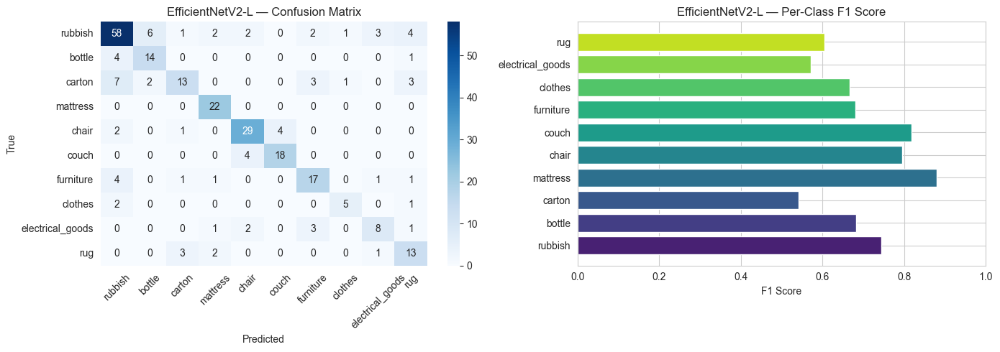

In [44]:
# Train EfficientNetV2-L
cfg = CLASSIFIER_CONFIGS[2]
clf_model_l, hist_l, path_l = train_classifier(
    cfg["model_name"], crop_records["train"], crop_records["val"],
    img_size=cfg["img_size"], lr=cfg["lr"], batch_size=cfg["batch_size"],
    save_name="effnetv2_l"
)

# Evaluate on test set
clf_results["EfficientNetV2-L"] = evaluate_classifier_full(
    clf_model_l, crop_records["test"], img_size=384, title="EfficientNetV2-L"
)
del clf_model_l
gc.collect()
torch.cuda.empty_cache()

#### EfficientNetV2-L training curves

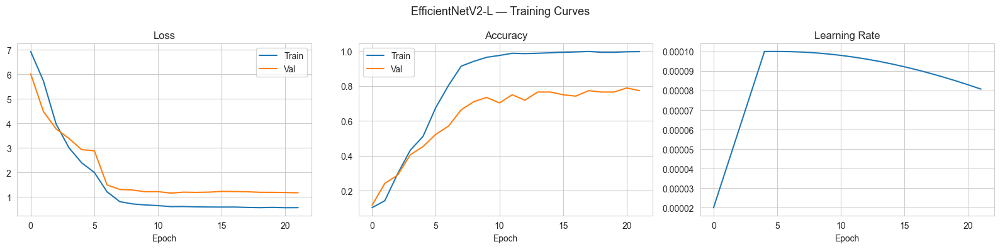

In [45]:
plot_classifier_curves(hist_l, "EfficientNetV2-L — Training Curves")

### 6d. Evaluate Classifiers on Test Crops

In [46]:
# Classifier test evaluation already done after each training run
for name, res in clf_results.items():
    display(f"{name}: Accuracy={res['accuracy']:.4f}, Macro F1={res['macro_f1']:.4f}")

'EfficientNetV2-S: Accuracy=0.7007, Macro F1=0.6497'

'EfficientNetV2-M: Accuracy=0.7007, Macro F1=0.6673'

'EfficientNetV2-L: Accuracy=0.7190, Macro F1=0.6984'

#### Classifier comparison table

In [47]:
clf_comparison_rows = []
for name, res in clf_results.items():
    clf_comparison_rows.append({
        "Model": name,
        "Accuracy": f"{res['accuracy']:.4f}",
        "Macro F1": f"{res['macro_f1']:.4f}",
    })

pd.DataFrame(clf_comparison_rows).style.hide(axis="index")

Model,Accuracy,Macro F1
EfficientNetV2-S,0.7007,0.6497
EfficientNetV2-M,0.7007,0.6673
EfficientNetV2-L,0.7190,0.6984


## 7. End-to-End Evaluation

For each matched pair (Small-Small, Medium-Medium, Large-Large):
1. Run binary detector on test images to get predicted boxes
2. Crop predicted boxes and run classifier
3. Evaluate using mAP@0.5 and mAP@0.5:0.95

In [48]:
def compute_iou(box1, box2):
    """Compute IoU between two boxes in [x1,y1,x2,y2] format."""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0


def yolo_to_xyxy(cx, cy, w, h, img_w, img_h):
    """Convert normalized YOLO coords to pixel [x1,y1,x2,y2]."""
    x1 = (cx - w / 2) * img_w
    y1 = (cy - h / 2) * img_h
    x2 = (cx + w / 2) * img_w
    y2 = (cy + h / 2) * img_h
    return [x1, y1, x2, y2]


def compute_ap(precisions, recalls):
    """Compute Average Precision using 101-point interpolation."""
    mrec = np.concatenate(([0.0], recalls, [1.0]))
    mpre = np.concatenate(([1.0], precisions, [0.0]))

    # Make precision monotonically decreasing
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])

    # 101-point interpolation
    recall_thresholds = np.linspace(0, 1, 101)
    precision_interp = np.zeros_like(recall_thresholds)
    for i, r in enumerate(recall_thresholds):
        above = mpre[mrec >= r]
        if len(above) > 0:
            precision_interp[i] = above.max()

    return precision_interp.mean()


def evaluate_detections(all_predictions, all_ground_truths, iou_threshold=0.5, num_classes=NUM_CLASSES):
    """
    Evaluate end-to-end detections.

    all_predictions: list of dicts per image: [{"boxes": [[x1,y1,x2,y2],...], "classes": [...], "scores": [...]}]
    all_ground_truths: list of dicts per image: [{"boxes": [[x1,y1,x2,y2],...], "classes": [...]}]

    Returns per-class AP and overall mAP.
    """
    per_class_ap = {}

    for cls_id in range(num_classes):
        # Collect all predictions and GTs for this class
        all_dets = []  # (score, is_tp, img_idx)
        n_gt = 0

        for img_idx, (preds, gts) in enumerate(zip(all_predictions, all_ground_truths)):
            gt_boxes = [b for b, c in zip(gts["boxes"], gts["classes"]) if c == cls_id]
            gt_matched = [False] * len(gt_boxes)
            n_gt += len(gt_boxes)

            pred_indices = [i for i, c in enumerate(preds["classes"]) if c == cls_id]
            pred_boxes = [preds["boxes"][i] for i in pred_indices]
            pred_scores = [preds["scores"][i] for i in pred_indices]

            # Sort by score descending
            sorted_idx = np.argsort(pred_scores)[::-1]

            for si in sorted_idx:
                pb = pred_boxes[si]
                score = pred_scores[si]
                best_iou = 0
                best_gt = -1
                for gi, gb in enumerate(gt_boxes):
                    iou = compute_iou(pb, gb)
                    if iou > best_iou:
                        best_iou = iou
                        best_gt = gi
                if best_iou >= iou_threshold and not gt_matched[best_gt]:
                    all_dets.append((score, True))
                    gt_matched[best_gt] = True
                else:
                    all_dets.append((score, False))

        if n_gt == 0:
            per_class_ap[cls_id] = 0.0
            continue

        # Sort all detections by score
        all_dets.sort(key=lambda x: x[0], reverse=True)

        tp_cumsum = np.cumsum([int(d[1]) for d in all_dets])
        fp_cumsum = np.cumsum([int(not d[1]) for d in all_dets])
        precisions = tp_cumsum / (tp_cumsum + fp_cumsum)
        recalls = tp_cumsum / n_gt

        per_class_ap[cls_id] = compute_ap(precisions, recalls)

    mAP = np.mean(list(per_class_ap.values()))
    return per_class_ap, mAP

In [49]:
@torch.no_grad()
def classify_crops_batch(model, crops_pil, img_size, device):
    """Classify a batch of PIL image crops. Returns predicted class IDs and confidences."""
    if not crops_pil:
        return [], []

    transform = get_val_transform(img_size)
    tensors = []
    for crop in crops_pil:
        img_np = np.array(crop.convert("RGB"))
        transformed = transform(image=img_np)
        tensors.append(transformed["image"])

    batch = torch.stack(tensors).to(device)
    model.eval()
    outputs = model(batch)
    probs = torch.softmax(outputs, dim=1)
    confs, preds = probs.max(1)
    return preds.cpu().numpy().tolist(), confs.cpu().numpy().tolist()


def run_end_to_end(detector_path, classifier_model, clf_img_size,
                   test_entries, device, conf_threshold=0.25):
    """
    Run full two-stage pipeline on test entries.
    Returns predictions and ground truths for evaluation.
    """
    detector = YOLO(str(detector_path))

    all_predictions = []
    all_ground_truths = []
    total_gt_boxes = 0
    total_detected = 0

    for entry in tqdm(test_entries, desc="End-to-end eval"):
        img_path = entry["image"]
        img = Image.open(img_path).convert("RGB")
        W, H = img.size

        # Ground truth
        gt_boxes = []
        gt_classes = []
        for cls_id, cx, cy, bw, bh in entry["boxes"]:
            gt_boxes.append(yolo_to_xyxy(cx, cy, bw, bh, W, H))
            gt_classes.append(cls_id)

        total_gt_boxes += len(gt_boxes)

        # Stage 1: detect
        results = detector.predict(str(img_path), imgsz=960, conf=conf_threshold, verbose=False)
        det_boxes = []
        det_scores_raw = []

        if len(results[0].boxes) > 0:
            for box in results[0].boxes:
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                score = box.conf[0].cpu().item()
                det_boxes.append([float(x1), float(y1), float(x2), float(y2)])
                det_scores_raw.append(score)

        total_detected += len(det_boxes)

        # Stage 2: classify crops
        pred_classes = []
        pred_scores = []

        if det_boxes:
            crops = []
            for x1, y1, x2, y2 in det_boxes:
                # Expand by 15%
                bw = x2 - x1
                bh = y2 - y1
                x1e = max(0, x1 - bw * 0.075)
                y1e = max(0, y1 - bh * 0.075)
                x2e = min(W, x2 + bw * 0.075)
                y2e = min(H, y2 + bh * 0.075)
                crop = img.crop((int(x1e), int(y1e), int(x2e), int(y2e)))
                crop = crop.resize((256, 256), Image.BILINEAR)
                crops.append(crop)

            cls_preds, cls_confs = classify_crops_batch(
                classifier_model, crops, clf_img_size, device
            )
            pred_classes = cls_preds
            # Combined score = detection score * classification confidence
            pred_scores = [ds * cc for ds, cc in zip(det_scores_raw, cls_confs)]

        all_predictions.append({
            "boxes": det_boxes,
            "classes": pred_classes,
            "scores": pred_scores,
        })
        all_ground_truths.append({
            "boxes": gt_boxes,
            "classes": gt_classes,
        })

    recall_stage1 = total_detected / max(total_gt_boxes, 1)
    return all_predictions, all_ground_truths, recall_stage1

In [50]:
# Reload classifier models for end-to-end evaluation
clf_model_s = create_model(CLASSIFIER_CONFIGS[0]["model_name"]).to(DEVICE)
clf_model_s.load_state_dict(torch.load(path_s, map_location=DEVICE))
clf_model_m = create_model(CLASSIFIER_CONFIGS[1]["model_name"]).to(DEVICE)
clf_model_m.load_state_dict(torch.load(path_m, map_location=DEVICE))
clf_model_l = create_model(CLASSIFIER_CONFIGS[2]["model_name"]).to(DEVICE)
clf_model_l.load_state_dict(torch.load(path_l, map_location=DEVICE))

# Test entries (only those with boxes for evaluation)
test_entries = [e for e in dataset_entries if e["split"] == "test" and e["boxes"]]

# Matched pairs: (detector_name, detector_path, classifier_name, classifier_model, clf_img_size)
PAIRS = [
    ("YOLO11s", binary_model_paths["YOLO11s"], "EfficientNetV2-S", clf_model_s, 256),
    ("YOLO11m", binary_model_paths["YOLO11m"], "EfficientNetV2-M", clf_model_m, 320),
    ("YOLO11l", binary_model_paths["YOLO11l"], "EfficientNetV2-L", clf_model_l, 384),
    ("YOLO26s", binary_model_paths["YOLO26s"], "EfficientNetV2-S", clf_model_s, 256),
    ("YOLO26m", binary_model_paths["YOLO26m"], "EfficientNetV2-M", clf_model_m, 320),
    ("YOLO26l", binary_model_paths["YOLO26l"], "EfficientNetV2-L", clf_model_l, 384),
]

e2e_results = {}

for det_name, det_path, clf_name, clf_model, clf_size in PAIRS:
    pair_name = f"{det_name} + {clf_name}"

    all_preds, all_gts, stage1_recall = run_end_to_end(
        det_path, clf_model, clf_size, test_entries, DEVICE
    )

    # Evaluate at IoU=0.5
    per_class_ap_50, mAP_50 = evaluate_detections(all_preds, all_gts, iou_threshold=0.5)

    # Evaluate at multiple IoU thresholds for mAP@0.5:0.95
    iou_thresholds = np.arange(0.5, 1.0, 0.05)
    maps_at_thresholds = []
    for iou_t in iou_thresholds:
        _, m = evaluate_detections(all_preds, all_gts, iou_threshold=iou_t)
        maps_at_thresholds.append(m)
    mAP_50_95 = np.mean(maps_at_thresholds)

    e2e_results[pair_name] = {
        "stage1_recall": stage1_recall,
        "mAP@0.5": mAP_50,
        "mAP@0.5:0.95": mAP_50_95,
        "per_class_ap_50": per_class_ap_50,
        "predictions": all_preds,
        "ground_truths": all_gts,
    }

End-to-end eval:   0%|          | 0/133 [00:00<?, ?it/s]

End-to-end eval:   0%|          | 0/133 [00:00<?, ?it/s]

End-to-end eval:   0%|          | 0/133 [00:00<?, ?it/s]

End-to-end eval:   0%|          | 0/133 [00:00<?, ?it/s]

End-to-end eval:   0%|          | 0/133 [00:00<?, ?it/s]

End-to-end eval:   0%|          | 0/133 [00:00<?, ?it/s]

### End-to-end mAP comparison table

In [51]:
e2e_rows = []
for pair_name, res in e2e_results.items():
    e2e_rows.append({
        "Pipeline": pair_name,
        "Stage 1 Recall": f"{res['stage1_recall']:.4f}",
        "mAP@0.5": f"{res['mAP@0.5']:.4f}",
        "mAP@0.5:0.95": f"{res['mAP@0.5:0.95']:.4f}",
    })

pd.DataFrame(e2e_rows).style.hide(axis="index")

Pipeline,Stage 1 Recall,mAP@0.5,mAP@0.5:0.95
YOLO11s + EfficientNetV2-S,0.9781,0.5074,0.4003
YOLO11m + EfficientNetV2-M,1.0474,0.5755,0.4650
YOLO11l + EfficientNetV2-L,1.0036,0.5500,0.4512
YOLO26s + EfficientNetV2-S,0.9234,0.4609,0.3621
YOLO26m + EfficientNetV2-M,0.9562,0.5678,0.4783
YOLO26l + EfficientNetV2-L,0.9234,0.5670,0.4608


### Per-class AP bar chart for each pair

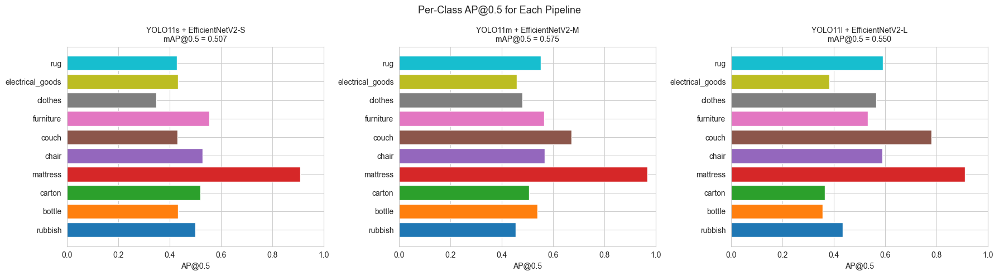

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (pair_name, res) in zip(axes, e2e_results.items()):
    aps = [res["per_class_ap_50"].get(i, 0) for i in range(NUM_CLASSES)]
    colors = [CLASS_COLORS[i] for i in range(NUM_CLASSES)]
    ax.barh(CLASS_NAMES, aps, color=colors)
    ax.set_xlim(0, 1)
    ax.set_title(f"{pair_name}\nmAP@0.5 = {res['mAP@0.5']:.3f}", fontsize=10)
    ax.set_xlabel("AP@0.5")

plt.suptitle("Per-Class AP@0.5 for Each Pipeline", fontsize=13)
plt.tight_layout()
plt.show()

### Sample test images with end-to-end predictions

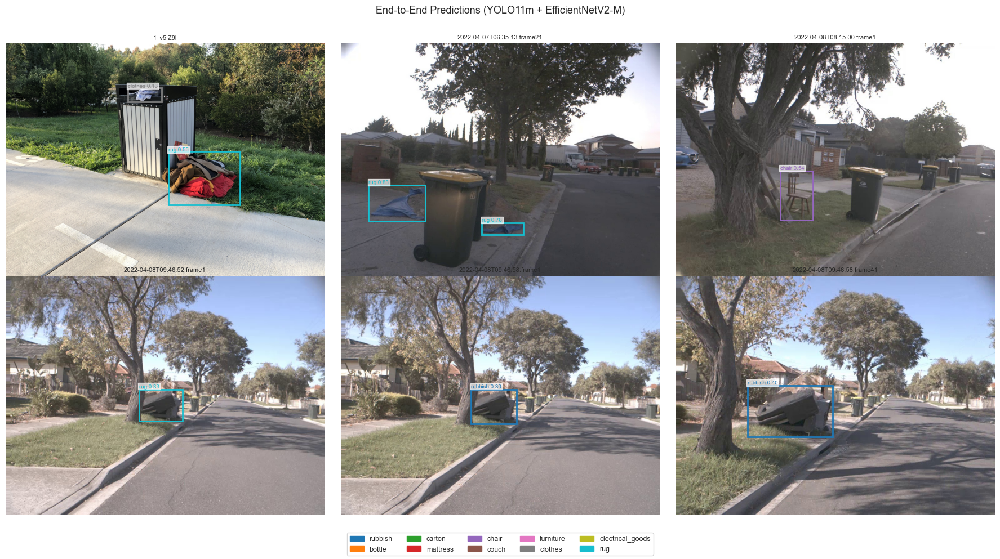

In [53]:
# Use the medium-medium pair for visualization
mid_pair = list(e2e_results.keys())[1]
mid_preds = e2e_results[mid_pair]["predictions"]
mid_gts = e2e_results[mid_pair]["ground_truths"]

# Pick images that have predictions
sample_indices = [i for i, p in enumerate(mid_preds) if len(p["boxes"]) > 0][:6]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, idx in zip(axes.flat, sample_indices):
    entry = test_entries[idx]
    img = Image.open(entry["image"]).convert("RGB")
    ax.imshow(np.array(img))

    # Draw predictions
    preds = mid_preds[idx]
    for box, cls_id, score in zip(preds["boxes"], preds["classes"], preds["scores"]):
        x1, y1, x2, y2 = box
        color = CLASS_COLORS.get(cls_id, (1, 0, 0, 1))
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                 linewidth=2, edgecolor=color, facecolor="none")
        ax.add_patch(rect)
        ax.text(x1, y1 - 5, f"{CLASS_NAMES[cls_id]} {score:.2f}", color=color,
                fontsize=7, fontweight="bold",
                bbox=dict(facecolor="white", alpha=0.7, pad=1))
    ax.axis("off")
    ax.set_title(entry["stem"][:30], fontsize=8)

# Handle case where fewer than 6 images
for ax in axes.flat[len(sample_indices):]:
    ax.axis("off")

legend_patches = [patches.Patch(color=CLASS_COLORS[i], label=CLASS_NAMES[i]) for i in range(NUM_CLASSES)]
fig.legend(handles=legend_patches, loc="lower center", ncol=5, fontsize=9)
fig.suptitle(f"End-to-End Predictions ({mid_pair})", fontsize=13)
plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

### 7.4 Save all end-to-end test predictions to disk

In [54]:
# Save ALL test images with end-to-end predicted bounding boxes for each size pair
for pair_name, pair_data in e2e_results.items():
    # Derive a clean folder name, e.g. twostage_yolo11s_effnetv2s_predictions
    safe_name = pair_name.lower().replace(" ", "_").replace("-", "_").replace("+", "_")
    save_dir = Path(f"twostage_{safe_name}_predictions")
    save_dir.mkdir(exist_ok=True)

    preds_list = pair_data["predictions"]

    for idx, entry in enumerate(tqdm(test_entries, desc=f"Saving {pair_name}")):
        img = Image.open(entry["image"]).convert("RGB")
        fig, ax = plt.subplots(1, 1, figsize=(12, 8))
        ax.imshow(np.array(img))

        preds = preds_list[idx]
        for box, cls_id, score in zip(preds["boxes"], preds["classes"], preds["scores"]):
            x1, y1, x2, y2 = box
            color = CLASS_COLORS.get(cls_id, (1, 0, 0, 1))
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                     linewidth=2, edgecolor=color, facecolor="none")
            ax.add_patch(rect)
            ax.text(x1, y1 - 5, f"{CLASS_NAMES[cls_id]} {score:.2f}", color=color,
                    fontsize=7, fontweight="bold",
                    bbox=dict(facecolor="white", alpha=0.7, pad=1))
        ax.axis("off")
        fig.savefig(save_dir / f"{entry['stem']}.jpg", bbox_inches="tight", dpi=150)
        plt.close(fig)

    f"{pair_name}: saved {len(test_entries)} predictions to {save_dir}"


Saving YOLO11s + EfficientNetV2-S:   0%|          | 0/133 [00:00<?, ?it/s]

Saving YOLO11m + EfficientNetV2-M:   0%|          | 0/133 [00:00<?, ?it/s]

Saving YOLO11l + EfficientNetV2-L:   0%|          | 0/133 [00:00<?, ?it/s]

Saving YOLO26s + EfficientNetV2-S:   0%|          | 0/133 [00:00<?, ?it/s]

Saving YOLO26m + EfficientNetV2-M:   0%|          | 0/133 [00:00<?, ?it/s]

Saving YOLO26l + EfficientNetV2-L:   0%|          | 0/133 [00:00<?, ?it/s]

### Stage 1 recall analysis

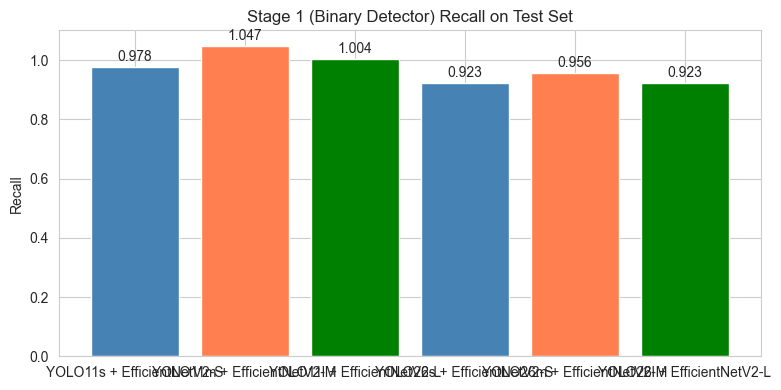

In [55]:
fig, ax = plt.subplots(figsize=(8, 4))
pair_names = list(e2e_results.keys())
recalls = [e2e_results[p]["stage1_recall"] for p in pair_names]
bars = ax.bar(pair_names, recalls, color=["steelblue", "coral", "green"])
ax.set_ylim(0, 1.1)
ax.set_ylabel("Recall")
ax.set_title("Stage 1 (Binary Detector) Recall on Test Set")
for bar, val in zip(bars, recalls):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f"{val:.3f}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

## 8. Compare All Models

### Comprehensive summary table

In [56]:
# Minority classes: bottle (1), mattress (3), couch (5), electrical_goods (8), clothes (7)
MINORITY_IDS = [1, 3, 5, 7, 8]

summary_rows = []
for pair_name, res in e2e_results.items():
    det_name = pair_name.split(" + ")[0]
    clf_name = pair_name.split(" + ")[1]

    # Get classifier accuracy for this size
    clf_acc = clf_results.get(clf_name, {}).get("accuracy", 0)

    # Minority class macro AP
    minority_aps = [res["per_class_ap_50"].get(i, 0) for i in MINORITY_IDS]
    minority_macro_ap = np.mean(minority_aps)

    summary_rows.append({
        "Detector": det_name,
        "Classifier": clf_name,
        "Stage 1 Recall": f"{res['stage1_recall']:.4f}",
        "Stage 2 Accuracy": f"{clf_acc:.4f}",
        "mAP@0.5": f"{res['mAP@0.5']:.4f}",
        "mAP@0.5:0.95": f"{res['mAP@0.5:0.95']:.4f}",
        "Minority mAP@0.5": f"{minority_macro_ap:.4f}",
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.style.hide(axis="index")

Detector,Classifier,Stage 1 Recall,Stage 2 Accuracy,mAP@0.5,mAP@0.5:0.95,Minority mAP@0.5
YOLO11s,EfficientNetV2-S,0.9781,0.7007,0.5074,0.4003,0.5093
YOLO11m,EfficientNetV2-M,1.0474,0.7007,0.5755,0.4650,0.6225
YOLO11l,EfficientNetV2-L,1.0036,0.7190,0.5500,0.4512,0.5981
YOLO26s,EfficientNetV2-S,0.9234,0.7007,0.4609,0.3621,0.4760
YOLO26m,EfficientNetV2-M,0.9562,0.7007,0.5678,0.4783,0.6254
YOLO26l,EfficientNetV2-L,0.9234,0.7190,0.5670,0.4608,0.6112


### End-to-end mAP comparison bar charts

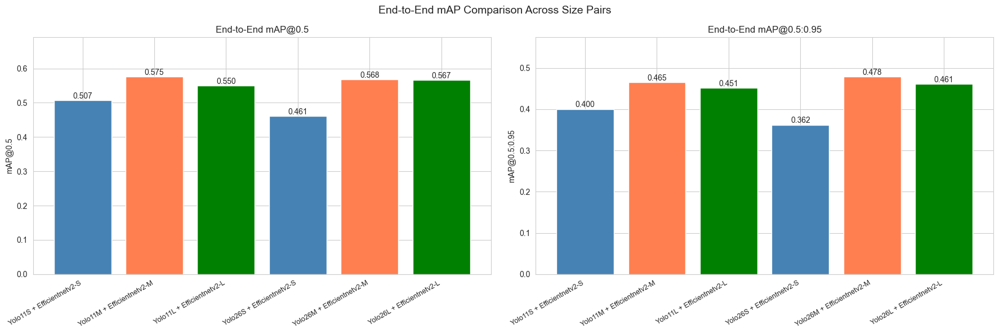

In [59]:
import matplotlib.pyplot as plt

# Prepare keys and labels
pair_keys = list(e2e_results.keys())
pair_labels = [k.replace("_", "-").title() for k in pair_keys]

# Expand colors if needed
base_colors = ["steelblue", "coral", "green"]
colors = (base_colors * (len(pair_keys) // len(base_colors) + 1))[:len(pair_keys)]

# Create figure
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

map50_vals = [e2e_results[k]["mAP@0.5"] for k in pair_keys]

bars1 = axes[0].bar(pair_labels, map50_vals, color=colors)
axes[0].set_ylabel("mAP@0.5")
axes[0].set_title("End-to-End mAP@0.5")
axes[0].set_ylim(0, max(map50_vals) * 1.2 if max(map50_vals) > 0 else 1)

for bar, val in zip(bars1, map50_vals):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{val:.3f}",
        ha="center",
        fontsize=10
    )

map5095_vals = [e2e_results[k]["mAP@0.5:0.95"] for k in pair_keys]

bars2 = axes[1].bar(pair_labels, map5095_vals, color=colors)
axes[1].set_ylabel("mAP@0.5:0.95")
axes[1].set_title("End-to-End mAP@0.5:0.95")
axes[1].set_ylim(0, max(map5095_vals) * 1.2 if max(map5095_vals) > 0 else 1)

for bar, val in zip(bars2, map5095_vals):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{val:.3f}",
        ha="center",
        fontsize=10
    )

for ax in axes:
    ax.set_xticks(range(len(pair_labels)))
    ax.set_xticklabels(pair_labels, rotation=30, ha="right")
    ax.tick_params(axis='x', labelsize=9)

plt.suptitle("End-to-End mAP Comparison Across Size Pairs", fontsize=14)
plt.tight_layout()

plt.show()

### Best combination

In [60]:
best_pair = max(e2e_results.items(), key=lambda x: x[1]["mAP@0.5"])
best_name = best_pair[0]
best_map50 = best_pair[1]["mAP@0.5"]
best_map5095 = best_pair[1]["mAP@0.5:0.95"]

results_summary = {
    "Best Pipeline": best_name,
    "mAP@0.5": f"{best_map50:.4f}",
    "mAP@0.5:0.95": f"{best_map5095:.4f}",
    "Stage 1 Recall": f"{best_pair[1]['stage1_recall']:.4f}",
}

pd.DataFrame([results_summary]).style.hide(axis="index")

Best Pipeline,mAP@0.5,mAP@0.5:0.95,Stage 1 Recall
YOLO11m + EfficientNetV2-M,0.5755,0.4650,1.0474
